# Part II
**Colab 使用方式**:Runtime 用 CPU 即可;由上而下依序執行(**Run all**)。不需上傳任何檔案——`nn_numpy.py` 會由下面的 `%%writefile` 儲存格自動產生;**CIFAR-10 第一次執行會下載並存進 Drive(`MyDrive/HW3_data/`),之後直接讀快取**。
結果(圖、json、`nn_numpy.py`)會存到 Google Drive 的 `MyDrive/HW3_results/`。

In [1]:
import os, sys, json, copy, random, shutil, time, itertools
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
random.seed(0); np.random.seed(0)

SMOKE = False
USE_DRIVE = True     # True: 掛載 Google Drive 並把結果存到 MyDrive/HW3_results
EP = 2 if SMOKE else 10
EP_C = 2 if SMOKE else 5

SAVE_DIR, DATA_DIR = './results', './data'
ON_COLAB = False
if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        SAVE_DIR  = '/content/drive/MyDrive/HW3_results'     # 圖、表、json、nn_numpy.py、submission
        DATA_DIR  = '/content/drive/MyDrive/HW3_data'        # CIFAR-10 快取(只下載一次)
        ON_COLAB = True
    except Exception as e:
        print('Not on Colab / Drive unavailable -> using local folders.', e)
os.makedirs(SAVE_DIR, exist_ok=True); os.makedirs(DATA_DIR, exist_ok=True)
print('SAVE_DIR =', SAVE_DIR, '| DATA_DIR =', DATA_DIR)
RESULTS = {}

Not on Colab / Drive unavailable -> using local folders. No module named 'google.colab'
SAVE_DIR = ./results | DATA_DIR = ./data


## 0. 模組 `nn_numpy.py`(寫入檔案,作業需一併繳交)

In [2]:
%%writefile nn_numpy.py
"""NumPy-only neural-network building blocks for HW3 Part II (no autograd, no sklearn)."""
import numpy as np

# ---------------------------------------------------------------- layers
def affine_forward(X, W, b):
    Z = X @ W + b
    return Z, (X, W)

def affine_backward(dZ, cache):
    X, W = cache
    return dZ @ W.T, X.T @ dZ, dZ.sum(axis=0)          # dX, dW, db

def relu_forward(X):
    return np.maximum(0, X), X

def relu_backward(dA, cache):
    return dA * (cache > 0)

def sigmoid_forward(X):
    A = 1.0 / (1.0 + np.exp(-X))
    return A, A

def sigmoid_backward(dA, cache):
    return dA * cache * (1.0 - cache)

# ---------------------------------------------------------------- losses
def softmax_ce_loss(S, y):
    """Mean softmax cross-entropy over the batch and dJ/dS."""
    N = S.shape[0]
    Z = S - S.max(axis=1, keepdims=True)                # numerical stability
    logsum = np.log(np.exp(Z).sum(axis=1, keepdims=True))
    logp = Z - logsum
    loss = -logp[np.arange(N), y].mean()
    dS = np.exp(logp)
    dS[np.arange(N), y] -= 1.0
    return loss, dS / N

def hinge_loss(S, y, delta=1.0):
    """Mean multiclass hinge loss sum_{j!=y} max(0, s_j - s_y + delta) and dJ/dS."""
    N = S.shape[0]
    idx = np.arange(N)
    margins = np.maximum(0.0, S - S[idx, y][:, None] + delta)
    margins[idx, y] = 0.0
    loss = margins.sum() / N
    dS = (margins > 0).astype(S.dtype)
    dS[idx, y] = -dS.sum(axis=1)
    return loss, dS / N

# ---------------------------------------------------------------- gradient check
def numerical_gradient(f, x, h=1e-5):
    """Centered finite differences of scalar function f w.r.t. array x (x is perturbed in place, then restored)."""
    grad = np.zeros_like(x)
    it = np.nditer(x, flags=['multi_index'], op_flags=['readwrite'])
    while not it.finished:
        i = it.multi_index
        old = x[i]
        x[i] = old + h; fp = f()
        x[i] = old - h; fm = f()
        x[i] = old
        grad[i] = (fp - fm) / (2 * h)
        it.iternext()
    return grad

def rel_error(a, n):
    return np.max(np.abs(a - n) / np.maximum(1e-8, np.abs(a) + np.abs(n)))

# ---------------------------------------------------------------- fully-connected net
class FCNet:
    """affine - act - affine - act ... - affine, with L2 regularisation  J = data + 0.5*reg*sum(W^2)."""
    def __init__(self, dims, act='relu', init='he', std=1e-2, reg=0.0, loss='softmax',
                 dtype=np.float32, seed=0):
        rng = np.random.RandomState(seed)
        self.act, self.reg, self.loss_name, self.L = act, reg, loss, len(dims) - 1
        self.p = {}
        for i in range(self.L):
            fi, fo = dims[i], dims[i + 1]
            if init == 'zero':   w = np.zeros((fi, fo))
            elif init == 'he':   w = rng.randn(fi, fo) * np.sqrt(2.0 / fi)
            else:                w = rng.randn(fi, fo) * std      # 'small' / 'large' / baseline: pass std
            self.p[f'W{i+1}'] = w.astype(dtype)
            self.p[f'b{i+1}'] = np.zeros(fo, dtype=dtype)
        self._f = relu_forward if act == 'relu' else sigmoid_forward
        self._b = relu_backward if act == 'relu' else sigmoid_backward

    def loss(self, X, y=None):
        caches, A = [], X
        for i in range(1, self.L + 1):
            A, c = affine_forward(A, self.p[f'W{i}'], self.p[f'b{i}']); caches.append(('a', c))
            if i < self.L:
                A, c = self._f(A); caches.append(('n', c))
        if y is None:
            return A
        lf = softmax_ce_loss if self.loss_name == 'softmax' else hinge_loss
        data_loss, dS = lf(A, y)
        reg_loss = 0.5 * self.reg * sum((self.p[f'W{i}'] ** 2).sum() for i in range(1, self.L + 1))
        grads, d, i = {}, dS, self.L
        for kind, c in reversed(caches):
            if kind == 'a':
                d, dW, db = affine_backward(d, c)
                grads[f'W{i}'] = dW + self.reg * self.p[f'W{i}']
                grads[f'b{i}'] = db
                i -= 1
            else:
                d = self._b(d, c)
        return data_loss + reg_loss, grads

    def predict(self, X, bs=1000):
        return np.concatenate([self.loss(X[i:i+bs]).argmax(1) for i in range(0, len(X), bs)])

def train(net, Xtr, ytr, Xva, yva, lr=1e-3, epochs=10, bs=200, lr_decay=1.0, momentum=0.0, seed=0, verbose=True):
    """Mini-batch SGD (optional momentum). Returns history dict. Data loss + reg is logged per epoch."""
    rng = np.random.RandomState(seed)
    vel = {k: np.zeros_like(v) for k, v in net.p.items()}
    hist = dict(loss=[], train_acc=[], val_acc=[])
    N = len(Xtr)
    for ep in range(epochs):
        perm, tot = rng.permutation(N), 0.0
        for i in range(0, N, bs):
            idx = perm[i:i+bs]
            l, g = net.loss(Xtr[idx], ytr[idx])
            tot += float(l) * len(idx)
            for k in net.p:
                vel[k] = momentum * vel[k] - lr * g[k]
                net.p[k] += vel[k]
        lr *= lr_decay
        hist['loss'].append(tot / N)
        hist['train_acc'].append(float((net.predict(Xtr[:5000]) == ytr[:5000]).mean()))
        hist['val_acc'].append(float((net.predict(Xva) == yva).mean()))
        if verbose:
            print(f"epoch {ep+1:3d} loss {hist['loss'][-1]:.4f} train {hist['train_acc'][-1]:.4f} val {hist['val_acc'][-1]:.4f}")
    return hist

def layer_grad_magnitudes(net, X, y):
    """Mean |dJ/dW| of every layer at the current weights (used for the vanishing-gradient plot)."""
    _, g = net.loss(X, y)
    return [float(np.abs(g[f'W{i}']).mean()) for i in range(1, net.L + 1)]

# ---------------------------------------------------------------- self test
def run_gradcheck(verbose=True):
    """Gradient check in float64 on a small random network; returns {name: relative error}."""
    rng = np.random.RandomState(0)
    N, D, H, C = 12, 5, 4, 4
    X = rng.randn(N, D); y = rng.randint(0, C, N)
    Wt, bt = rng.randn(D, H), rng.randn(H)
    G = rng.randn(N, H)                                      # upstream gradient for the layer checks
    res = {}
    # affine
    Z, c = affine_forward(X, Wt, bt); dX, dW, db = affine_backward(G, c)
    f = lambda: (affine_forward(X, Wt, bt)[0] * G).sum()
    res['affine dX'] = rel_error(dX, numerical_gradient(f, X))
    res['affine dW'] = rel_error(dW, numerical_gradient(f, Wt))
    res['affine db'] = rel_error(db, numerical_gradient(f, bt))
    # activations
    Xa = rng.randn(N, H)
    for name, fw, bw in [('relu', relu_forward, relu_backward), ('sigmoid', sigmoid_forward, sigmoid_backward)]:
        _, c = fw(Xa); da = bw(G, c)
        res[f'{name} dX'] = rel_error(da, numerical_gradient(lambda: (fw(Xa)[0] * G).sum(), Xa))
    # losses
    S = rng.randn(N, C)
    for name, lf in [('softmax_ce', softmax_ce_loss), ('hinge', hinge_loss)]:
        _, dS = lf(S, y)
        res[f'{name} dS'] = rel_error(dS, numerical_gradient(lambda: lf(S, y)[0], S))
    # whole network, both activations / losses
    for act in ['relu', 'sigmoid']:
        for ls in ['softmax', 'hinge']:
            net = FCNet([D, 7, 6, C], act=act, init='he', reg=0.1, loss=ls, dtype=np.float64)
            for k in net.p: net.p[k] += 0.1 * rng.randn(*net.p[k].shape)
            _, g = net.loss(X, y)
            for k in net.p:
                n = numerical_gradient(lambda: net.loss(X, y)[0], net.p[k])
                res[f'net[{act},{ls}] {k}'] = rel_error(g[k], n)
    if verbose:
        for k, v in res.items():
            print(f'{k:28s} {v:.2e}  {"OK" if v < 1e-6 else "FAIL"}')
        print('ALL < 1e-6:', all(v < 1e-6 for v in res.values()))
    return res

if __name__ == '__main__':
    run_gradcheck()

Writing nn_numpy.py


## (a) Gradient Check

In [3]:
import importlib, nn_numpy; importlib.reload(nn_numpy)
from nn_numpy import FCNet, train, layer_grad_magnitudes, run_gradcheck
res = run_gradcheck(verbose=False)
df = pd.DataFrame({'relative error': res}); df['< 1e-6'] = df['relative error'] < 1e-6
pd.set_option('display.max_rows', 100)
display(df.style.format({'relative error': '{:.2e}'}))
print('ALL < 1e-6:', bool(df['< 1e-6'].all()), '| max =', f"{df['relative error'].max():.2e}")
RESULTS['gradcheck_max'] = float(df['relative error'].max())

,relative error,< 1e-6
affine dX,1.22e-09,True
affine dW,4.12e-10,True
affine db,4.63e-11,True
relu dX,2.17e-09,True
sigmoid dX,2.33e-08,True
softmax_ce dS,1.14e-09,True
hinge dS,6.99e-11,True
"net[relu,softmax] W1",2.14e-09,True
"net[relu,softmax] b1",3.87e-10,True
"net[relu,softmax] W2",1.08e-07,True


ALL < 1e-6: True | max = 1.08e-07


## 資料:CIFAR-10(只下載一次,之後直接讀 Drive 快取)
- 前 45,000 張為訓練、最後 5,000 張為驗證(不洗牌);平均影像只用前 45,000 張計算。

In [4]:
CACHE = os.path.join(DATA_DIR, 'cifar10_uint8.npz')

def get_cifar10_train():
    if os.path.exists(CACHE):
        try:
            z = np.load(CACHE)                                   # npz 是延遲讀取:只會讀下面兩個 key
            xt, yt = z['x_train'], z['y_train']
            assert xt.shape == (50000, 32, 32, 3) and yt.shape == (50000,)
            print('Loaded CIFAR-10 from cache:', CACHE)
            return xt, yt
        except Exception as e:
            print('Cache unreadable -> will re-download:', e)
    print('Cache not found -> downloading CIFAR-10 (one-time) ...')
    from torchvision.datasets import CIFAR10                     # 只當資料下載器(handout 允許)
    raw = '/content/cifar10_raw' if ON_COLAB else './cifar10_raw'
    tr = CIFAR10(raw, train=True, download=True); te = CIFAR10(raw, train=False, download=True)
    xt, yt = tr.data, np.asarray(tr.targets, dtype=np.int64)
    tmp = CACHE + '.tmp.npz'
    np.savez(tmp, x_train=xt, y_train=yt, x_test=te.data, y_test=np.asarray(te.targets, dtype=np.int64))
    os.replace(tmp, CACHE)                                       # 先寫暫存再改名,避免留下寫到一半的壞檔
    print('Saved cache ->', CACHE, f'({os.path.getsize(CACHE) / 1e6:.0f} MB)')
    return xt, yt

def load_data():
    if SMOKE:
        r = np.random.RandomState(0)
        return (r.randn(900, 3072).astype(np.float32), r.randint(0, 10, 900),
                r.randn(100, 3072).astype(np.float32), r.randint(0, 10, 100))
    xt, yt = get_cifar10_train()
    x = xt.astype(np.float32) / 255.0                            # [0,1]
    mean = x[:45000].mean(axis=0, dtype=np.float64).astype(np.float32)
    x = (x - mean).reshape(50000, 3072)
    y = yt.astype(np.int64)
    return x[:45000], y[:45000], x[45000:], y[45000:]            # 最後 5,000 = 驗證

Xtr, ytr, Xva, yva = load_data()
print('train', Xtr.shape, 'val', Xva.shape, '| class counts (train):', np.bincount(ytr))

Loaded CIFAR-10 from cache: ./data\cifar10_uint8.npz
train (45000, 3072) val (5000, 3072) | class counts (train): [4507 4512 4521 4481 4525 4471 4512 4515 4468 4488]


## (b-1) 先過擬合 50 張影像

after 50 epochs: loss=0.0024  train acc on the 50 images=100.00%


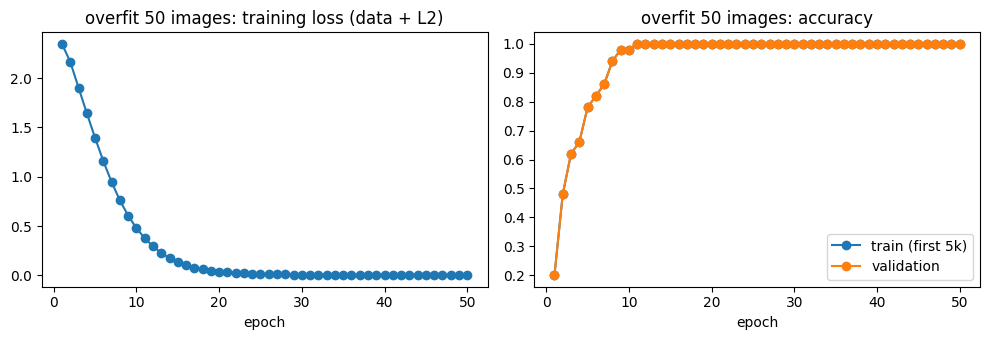

In [5]:
def plot_curves(h, title, fname=None):
    ep = range(1, len(h['loss']) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
    ax[0].plot(ep, h['loss'], marker='o'); ax[0].set(title=f'{title}: training loss (data + L2)', xlabel='epoch')
    ax[1].plot(ep, h['train_acc'], marker='o', label='train (first 5k)'); ax[1].plot(ep, h['val_acc'], marker='o', label='validation')
    ax[1].set(title=f'{title}: accuracy', xlabel='epoch'); ax[1].legend(); plt.tight_layout()
    if fname: plt.savefig(os.path.join(SAVE_DIR, fname), dpi=150, bbox_inches='tight')
    plt.show()
net = FCNet([3072, 100, 10], init='he', reg=0.0)
h50 = train(net, Xtr[:50], ytr[:50], Xtr[:50], ytr[:50], lr=5e-2, epochs=50, bs=50, momentum=0.9, verbose=False)
print(f"after 50 epochs: loss={h50['loss'][-1]:.4f}  train acc on the 50 images={h50['val_acc'][-1]:.2%}")
plot_curves(h50, 'overfit 50 images', 'ii_overfit50.png')
RESULTS['overfit50'] = dict(loss=h50['loss'][-1], acc=h50['val_acc'][-1])

{'hidden': 100, 'lr': 0.01, 'L2': 0.0, 'init': 'He', 'momentum': 0.9, 'train_acc': 0.5824, 'val_acc': 0.5154, 'sec': 26}
{'hidden': 100, 'lr': 0.01, 'L2': 0.001, 'init': 'He', 'momentum': 0.9, 'train_acc': 0.5726, 'val_acc': 0.5156, 'sec': 26}
{'hidden': 100, 'lr': 0.01, 'L2': 0.01, 'init': 'He', 'momentum': 0.9, 'train_acc': 0.5162, 'val_acc': 0.4842, 'sec': 30}
{'hidden': 100, 'lr': 0.03, 'L2': 0.0, 'init': 'He', 'momentum': 0.9, 'train_acc': 0.6396, 'val_acc': 0.525, 'sec': 28}
{'hidden': 100, 'lr': 0.03, 'L2': 0.001, 'init': 'He', 'momentum': 0.9, 'train_acc': 0.6234, 'val_acc': 0.5326, 'sec': 27}
{'hidden': 100, 'lr': 0.03, 'L2': 0.01, 'init': 'He', 'momentum': 0.9, 'train_acc': 0.522, 'val_acc': 0.4986, 'sec': 24}
{'hidden': 512, 'lr': 0.01, 'L2': 0.0, 'init': 'He', 'momentum': 0.9, 'train_acc': 0.6272, 'val_acc': 0.5356, 'sec': 114}
{'hidden': 512, 'lr': 0.01, 'L2': 0.001, 'init': 'He', 'momentum': 0.9, 'train_acc': 0.6132, 'val_acc': 0.538, 'sec': 99}
{'hidden': 512, 'lr': 0.01

,hidden,lr,L2,init,momentum,train_acc,val_acc,sec
cfg1,512,0.03,0.001,He,0.900000,0.6938,0.5524,81
cfg2,512,0.03,0,He,0.900000,0.7302,0.5482,71
cfg3,512,0.01,0.001,He,0.900000,0.6132,0.5380,99
cfg4,512,0.01,0,He,0.900000,0.6272,0.5356,114
cfg5,100,0.03,0.001,He,0.900000,0.6234,0.5326,27
cfg6,100,0.03,0,He,0.900000,0.6396,0.5250,28
cfg7,100,0.01,0.001,He,0.900000,0.5726,0.5156,26
cfg8,100,0.01,0,He,0.900000,0.5824,0.5154,26
cfg9,512,0.03,0.01,He,0.900000,0.5388,0.4998,94
cfg10,100,0.03,0.01,He,0.900000,0.5220,0.4986,24


best config (hidden, lr, L2): (512, 0.03, 0.001) | val acc 0.5524


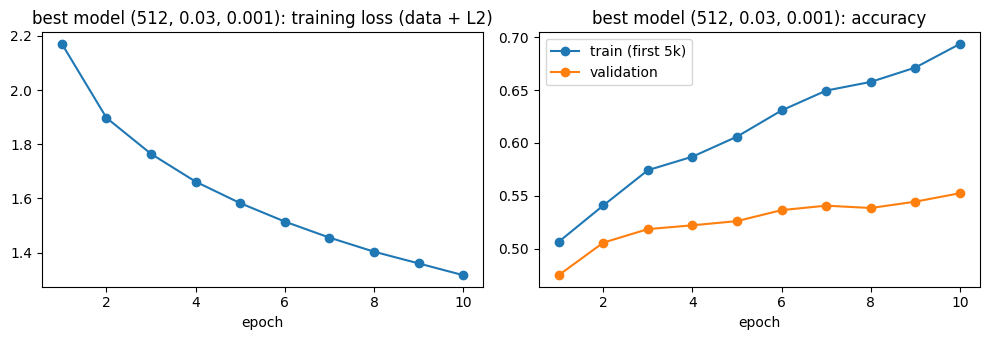

In [6]:
def run(hid, lr, reg, init='he', loss='softmax', epochs=EP, decay=0.95, mom=0.9, bs=200):
    net = FCNet([3072, hid, 10], init=init, std=1e-2, reg=reg, loss=loss)
    t = time.time()
    h = train(net, Xtr, ytr, Xva, yva, lr=lr, epochs=epochs, bs=bs, lr_decay=decay, momentum=mom, verbose=False)
    return net, h, time.time() - t

grid = list(itertools.product([100, 512], [1e-2, 3e-2], [0.0, 1e-3, 1e-2]))      # 12 組
if SMOKE: grid = grid[:4]
rows, best_net, best_hist, best_cfg, best_val = [], None, None, None, -1
for hid, lr, reg in grid:
    net, h, sec = run(hid, lr, reg)
    rows.append(dict(hidden=hid, lr=lr, L2=reg, init='He', momentum=0.9, train_acc=h['train_acc'][-1], val_acc=h['val_acc'][-1], sec=round(sec)))
    print(rows[-1])
    if h['val_acc'][-1] > best_val: best_net, best_hist, best_cfg, best_val = copy.deepcopy(net), h, (hid, lr, reg), h['val_acc'][-1]
tab = pd.DataFrame(rows).sort_values('val_acc', ascending=False).reset_index(drop=True)
tab.index = [f'cfg{i+1}' for i in range(len(tab))]
display(tab.style.format({'train_acc': '{:.4f}', 'val_acc': '{:.4f}', 'lr': '{:g}', 'L2': '{:g}'}))
print('best config (hidden, lr, L2):', best_cfg, '| val acc', round(best_val, 4))
tab.to_csv(os.path.join(SAVE_DIR, 'ii_config_table.csv')); RESULTS['best_cfg'] = best_cfg; RESULTS['best_val_acc'] = best_val
RESULTS['config_table'] = tab.reset_index().to_dict('records')
plot_curves(best_hist, f'best model {best_cfg}', 'ii_best_curves.png')

### Softmax vs Hinge

In [7]:
hid, lr, reg = best_cfg
rows = []
for ls in ['softmax', 'hinge']:
    for lr_ in [lr, lr / 3]:
        net, h, _ = run(hid, lr_, reg, loss=ls)
        rows.append(dict(loss=ls, lr=lr_, train_acc=h['train_acc'][-1], val_acc=h['val_acc'][-1]))
cmp = pd.DataFrame(rows); display(cmp.style.format({'train_acc': '{:.4f}', 'val_acc': '{:.4f}', 'lr': '{:g}'}))
RESULTS['loss_compare'] = rows

,loss,lr,train_acc,val_acc
0,softmax,0.03,0.6938,0.5524
1,softmax,0.01,0.6132,0.5380
2,hinge,0.03,0.7042,0.5140
3,hinge,0.01,0.7060,0.5354


## (c) Design Issues
**(i)+(ii)** 比較初始化(zero / small std=1e-2 / large std=1 / He)× 激活(ReLU / sigmoid):畫出**訓練開始時**每層權重的平均 $|\partial J/\partial W|$,並訓練後比較驗證準確率。

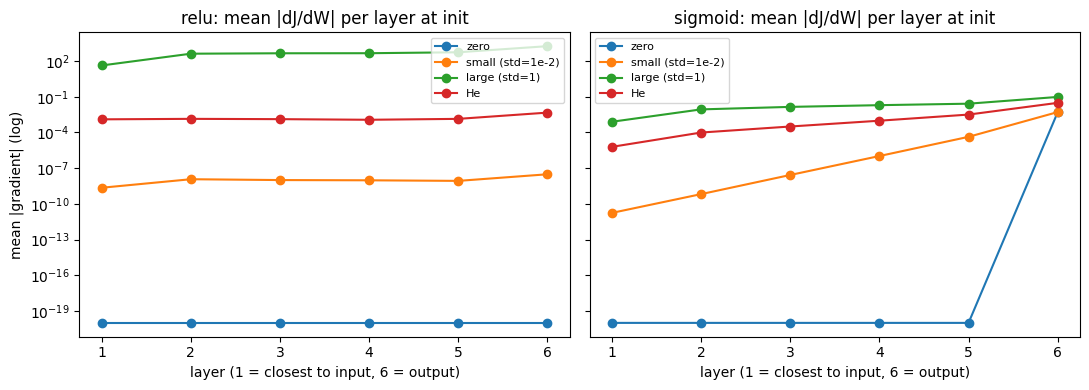

,W1,W2,W3,W4,W5,W6
relu / zero,0.0e+00,0.0e+00,0.0e+00,0.0e+00,0.0e+00,0.0e+00
relu / small (std=1e-2),2.3e-09,1.2e-08,1.0e-08,9.5e-09,8.5e-09,3.1e-08
relu / large (std=1),4.2e+01,4.1e+02,4.5e+02,4.5e+02,5.4e+02,1.8e+03
relu / He,1.3e-03,1.4e-03,1.3e-03,1.2e-03,1.4e-03,4.6e-03
sigmoid / zero,0.0e+00,0.0e+00,0.0e+00,0.0e+00,0.0e+00,5.0e-03
sigmoid / small (std=1e-2),1.7e-11,6.6e-10,2.7e-08,1.0e-06,4.3e-05,5.1e-03
sigmoid / large (std=1),7.9e-04,8.6e-03,1.4e-02,1.9e-02,2.6e-02,9.6e-02
sigmoid / He,6.1e-06,9.8e-05,3.1e-04,9.6e-04,3.2e-03,3.0e-02


,act,init,lr,final_loss,train_acc,val_acc
0,relu,zero,0.01,2.303,0.1038,0.0958
1,relu,small (std=1e-2),0.01,2.303,0.1038,0.0958
2,relu,large (std=1),0.0001,2.303,0.0972,0.0970
3,relu,He,0.01,1.313,0.5624,0.5010
4,sigmoid,zero,0.01,2.305,0.0976,0.1058
5,sigmoid,small (std=1e-2),0.01,2.305,0.0976,0.1058
6,sigmoid,large (std=1),0.0001,3.160,0.1082,0.1142
7,sigmoid,He,0.01,2.303,0.1082,0.1180


In [8]:
dims = [3072] + [100] * 5 + [10]
INITS = {'zero': dict(init='zero'), 'small (std=1e-2)': dict(init='std', std=1e-2),
         'large (std=1)': dict(init='std', std=1.0), 'He': dict(init='he')}
gm, tr_rows = {}, []
xb, yb = Xtr[:500], ytr[:500]
with np.errstate(all='ignore'):
    for act in ['relu', 'sigmoid']:
        for name, kw in INITS.items():
            net = FCNet(dims, act=act, **kw)
            gm[(act, name)] = layer_grad_magnitudes(net, xb, yb)
            lr_c = 1e-4 if 'large' in name else 1e-2
            h = train(net, Xtr, ytr, Xva, yva, lr=lr_c, epochs=EP_C, bs=200, momentum=0.9, verbose=False)
            tr_rows.append(dict(act=act, init=name, lr=lr_c, final_loss=h['loss'][-1], train_acc=h['train_acc'][-1], val_acc=h['val_acc'][-1]))
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, act in zip(ax, ['relu', 'sigmoid']):
    for name in INITS:
        a.semilogy(range(1, 7), np.maximum(gm[(act, name)], 1e-20), 'o-', label=name)
    a.set(title=f'{act}: mean |dJ/dW| per layer at init', xlabel='layer (1 = closest to input, 6 = output)'); a.legend(fontsize=8)
ax[0].set_ylabel('mean |gradient| (log)'); plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'ii_grad_flow.png'), dpi=150, bbox_inches='tight'); plt.show()
gdf = pd.DataFrame({f'{k[0]} / {k[1]}': v for k, v in gm.items()}, index=[f'W{i}' for i in range(1, 7)]).T
display(gdf.style.format('{:.1e}'))
tdf = pd.DataFrame(tr_rows); display(tdf.style.format({'final_loss': '{:.3f}', 'train_acc': '{:.4f}', 'val_acc': '{:.4f}', 'lr': '{:g}'}))
RESULTS['grad_mag'] = {f'{k[0]}/{k[1]}': v for k, v in gm.items()}; RESULTS['init_table'] = tr_rows

**(iii) L2 正則強度**

In [9]:
hid, lr, _ = best_cfg
regs = [0.0, 1e-3, 1e-2, 1e-1]
rows = []
for r_ in regs:
    net, h, _ = run(hid, lr, r_, epochs=EP)
    rows.append(dict(L2=r_, train_acc=h['train_acc'][-1], val_acc=h['val_acc'][-1], gap=h['train_acc'][-1] - h['val_acc'][-1],
                     W_norm=float(np.sqrt(sum((net.p[f'W{i}'] ** 2).sum() for i in (1, 2))))))
l2df = pd.DataFrame(rows); display(l2df.style.format({'train_acc': '{:.4f}', 'val_acc': '{:.4f}', 'gap': '{:.4f}', 'W_norm': '{:.2f}', 'L2': '{:g}'}))
RESULTS['l2'] = rows

,L2,train_acc,val_acc,gap,W_norm
0,0,0.7302,0.5482,0.1820,37.43
1,0.001,0.6938,0.5524,0.1414,24.65
2,0.01,0.5388,0.4998,0.0390,6.71
3,0.1,0.3304,0.3260,0.0044,1.79


In [10]:
RESULTS['best_model_val_acc_final'] = float((best_net.predict(Xva) == yva).mean())
def _clean(o):
    if isinstance(o, dict): return {str(k): _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [_clean(v) for v in o]
    if isinstance(o, (np.floating, np.integer)): return o.item()
    return o
json.dump(_clean(RESULTS), open(os.path.join(SAVE_DIR, 'part2_results.json'), 'w'), indent=1)
shutil.copy('nn_numpy.py', os.path.join(SAVE_DIR, 'nn_numpy.py'))
print('saved to', SAVE_DIR, '->', sorted(os.listdir(SAVE_DIR)))

saved to ./results -> ['final_cnn.pt', 'ii_best_curves.png', 'ii_config_table.csv', 'ii_grad_flow.png', 'ii_overfit50.png', 'iii_basic_cnn_curves.png', 'iii_final_curves.png', 'iii_my_cnn_curves.png', 'iii_my_cnn_layers.csv', 'iii_sens_cache.json', 'iii_sensitivity.png', 'nn_numpy.py', 'part2_results.json', 'part3_results.json', 'submission_CNN.csv']


In [11]:
%%writefile a3_submission.py
"""Submission formatting only; contains no model or model solution."""
from pathlib import Path
import csv
import numpy as np

EXPECTED_IDS = np.arange(45000, 50000, dtype=np.int64)

def export_submission(predictions, ids=None, path='submission.csv'):
    """Export 5,000 integer class predictions, paired with their image IDs."""
    predictions = np.asarray(predictions)
    ids = EXPECTED_IDS.copy() if ids is None else np.asarray(ids)
    if predictions.shape != (5000,) or ids.shape != (5000,):
        raise ValueError('Expected 5,000 class labels and 5,000 IDs; convert logits with argmax(axis=1).')
    if not np.issubdtype(predictions.dtype, np.integer) or not np.issubdtype(ids.dtype, np.integer):
        raise ValueError('Labels and IDs must use integer dtypes.')
    if not np.array_equal(np.sort(ids), EXPECTED_IDS):
        raise ValueError('IDs must contain each integer from 45000 to 49999 exactly once.')
    if np.any((predictions < 0) | (predictions > 9)):
        raise ValueError('Labels must be integers from 0 to 9.')
    order = np.argsort(ids)
    path = Path(path)
    with path.open('w', encoding='utf-8', newline='') as f:
        writer = csv.writer(f, lineterminator='\n')
        writer.writerow(['id', 'label'])
        writer.writerows(zip(ids[order].tolist(), predictions[order].tolist()))
    return path

Overwriting a3_submission.py


In [12]:
assert not SMOKE, "SMOKE=True 只是測試流程,請設回 False 再產生正式提交檔"
from a3_submission import export_submission
pred = best_net.predict(Xva).astype(np.int64)
ids = np.arange(45000, 50000)
path = export_submission(pred, ids, os.path.join(SAVE_DIR, 'submission_NN.csv'))
shutil.copy(path, 'submission_NN.csv')
chk = pd.read_csv('submission_NN.csv')
assert list(chk.columns) == ['id', 'label'] and len(chk) == 5000 and chk.label.between(0, 9).all()
print('saved:', path, '| rows:', len(chk), '| label counts:', np.bincount(chk.label, minlength=10))
try:
    from google.colab import files; files.download('submission_NN.csv')
except Exception: pass

saved: results\submission_NN.csv | rows: 5000 | label counts: [449 576 585 444 506 494 464 474 576 432]
